# Atividade 11 — Clusterização (K-Means e DBSCAN)

**Base:** Stellar Classification Dataset (SDSS17), versão tratada (`data/processed/star_classification_tratado.csv`).

**Objetivo:** agrupar os objetos em **3 clusters** (o número de classes: GALAXY, QSO e STAR) **sem usar a coluna `class`**, e depois verificar se os clusters encontrados correspondem às classes originais.

Roteiro:
1. Preparação dos dados (remoção da classe e engenharia de atributos)
2. K-Means (k = 3), com checagem pelo método do cotovelo e silhueta
3. DBSCAN, com escolha de `eps` e `min_samples`
4. Gráficos de dispersão com os clusters
5. Heatmaps de correlação entre clusters e atributos
6. Relação entre clusters e classes originais (tabelas cruzadas e métricas)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score,
                             completeness_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
AMOSTRA = 5000          # mesma amostra estratificada usada nas atividades de SVM e MLP
N_CLUSTERS = 3          # número de classes do problema

## 1. Carregamento e preparação dos dados

In [2]:
# Funciona rodando o notebook da pasta notebooks/ ou da raiz do repositório
caminho = Path("../data/processed/star_classification_tratado.csv")
if not caminho.exists():
    caminho = Path("data/processed/star_classification_tratado.csv")

df = pd.read_csv(caminho)

id_cols = ['obj_ID', 'run_ID', 'rerun_ID', 'cam_col', 'field_ID',
           'spec_obj_ID', 'plate', 'MJD', 'fiber_ID']
df = df.drop(columns=id_cols)

# Amostra estratificada (DBSCAN e silhueta ficam pesados com 100 mil pontos)
df, _ = train_test_split(df, train_size=AMOSTRA, random_state=RANDOM_STATE,
                         stratify=df['class'])
df = df.reset_index(drop=True)

print(df.shape)
df['class'].value_counts()

(5000, 9)


class
GALAXY    2972
STAR      1080
QSO        948
Name: count, dtype: int64

### Engenharia de atributos

Para clusterização, a forma de representar os dados importa muito, porque o algoritmo só enxerga **distâncias**:

- `alpha` e `delta` são a **posição no céu**. Não dizem nada sobre o tipo do objeto e, se entrarem, o algoritmo tende a agrupar por região do céu.
- As magnitudes `u, g, r, i, z` dependem muito do **brilho/distância** do objeto. Em astronomia, o que caracteriza o tipo é a **cor**, ou seja, a diferença entre filtros (`u−g`, `g−r`, `r−i`, `i−z`).
- O `redshift` é muito assimétrico (estrelas ≈ 0, quasares chegam a 7). O **log** deixa a escala mais equilibrada.

Mais abaixo comparo esse conjunto com os atributos originais.

In [3]:
df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']
df['r_i'] = df['r'] - df['i']
df['i_z'] = df['i'] - df['z']
# redshift tem alguns valores levemente negativos (estrelas); clip antes do log
df['log_redshift'] = np.log10(df['redshift'].clip(lower=1e-4) + 1e-3)

FEATURES = ['u_g', 'g_r', 'r_i', 'i_z', 'log_redshift']

# A coluna da classe fica guardada à parte, só para a avaliação final
y = df['class']
X = df[FEATURES]

# Padronização: K-Means e DBSCAN são baseados em distância e sensíveis à escala
X_scaled = StandardScaler().fit_transform(X)
X.describe().T

,count,mean,std,min,25%,50%,75%,max
u_g,5000.0,1.443995,1.175224,-3.753280,0.639547,1.340595,2.026003,9.379830
g_r,5000.0,0.986969,0.763447,-12.318610,0.383375,0.923135,1.584095,7.523890
r_i,5000.0,0.560356,0.532488,-7.747890,0.212683,0.476635,0.887765,10.730430
i_z,5000.0,0.306754,0.469407,-10.425100,0.138293,0.338950,0.471992,3.329380
log_redshift,5000.0,-0.911467,1.156822,-2.958607,-1.261347,-0.390965,-0.153653,0.845857


## 2. K-Means

A atividade pede k = número de classes (3). Antes, vale conferir o que o próprio dado "sugere" pelo **método do cotovelo** (inércia) e pela **silhueta**.

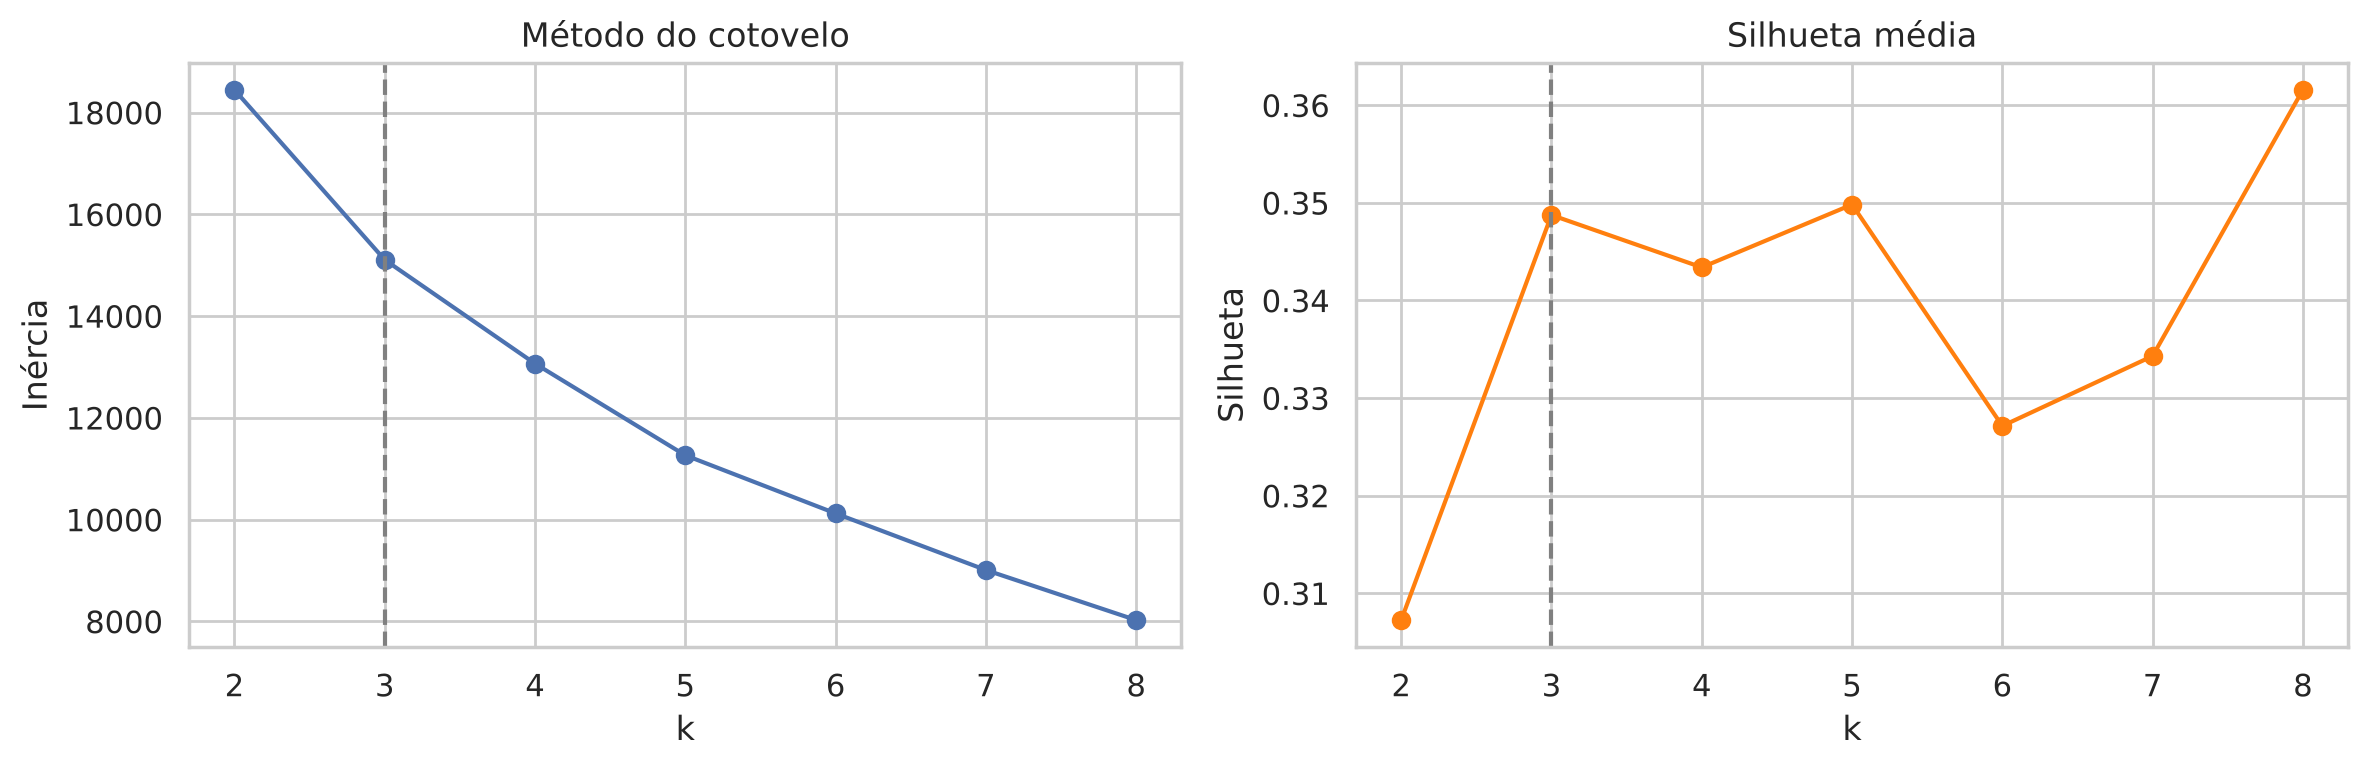

In [4]:
ks = range(2, 9)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inercias, 'o-'); ax[0].set(title='Método do cotovelo', xlabel='k', ylabel='Inércia')
ax[1].plot(ks, silhuetas, 'o-', color='tab:orange'); ax[1].set(title='Silhueta média', xlabel='k', ylabel='Silhueta')
for a in ax: a.axvline(N_CLUSTERS, ls='--', c='gray')
plt.tight_layout(); plt.show()

In [5]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

print('Silhueta K-Means:', round(silhouette_score(X_scaled, df['cluster_kmeans']), 3))
df['cluster_kmeans'].value_counts().sort_index()

Silhueta K-Means: 0.349


cluster_kmeans
0    1554
1     980
2    2466
Name: count, dtype: int64

## 3. DBSCAN

O DBSCAN não recebe o número de clusters. Ele depende de `eps` (raio de vizinhança) e `min_samples` (MinPts).

**Escolha dos parâmetros (sem olhar a classe):**
1. Gráfico de k-distância: o "joelho" da curva indica uma faixa razoável de `eps`.
2. Busca em grade, mantendo apenas combinações que geram **3 clusters**, com **no máximo 30% de ruído** e **nenhum cluster com menos de 5% dos pontos** (para evitar a solução trivial "um cluster gigante + dois minúsculos"), e escolhendo a de maior silhueta.

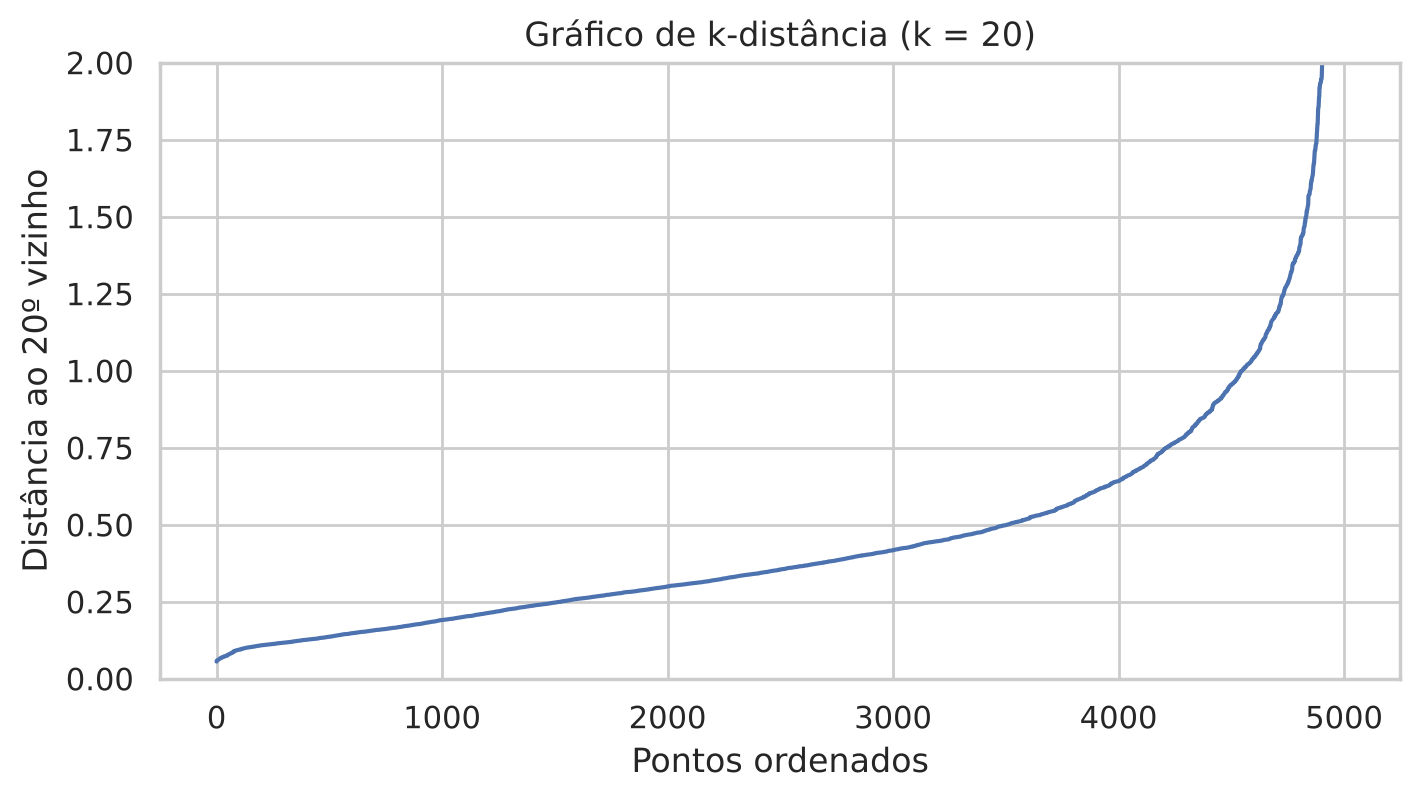

In [6]:
MIN_SAMPLES_REF = 20
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES_REF).fit(X_scaled)
dist, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.ylim(0, 2)
plt.title(f'Gráfico de k-distância (k = {MIN_SAMPLES_REF})')
plt.xlabel('Pontos ordenados'); plt.ylabel(f'Distância ao {MIN_SAMPLES_REF}º vizinho')
plt.show()

In [7]:
resultados = []
for eps in np.arange(0.20, 1.01, 0.05):
    for ms in [5, 10, 15, 20, 30]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(labels)) - (1 if -1 in labels else 0)
        ruido = (labels == -1).mean()
        sil = np.nan
        menor = pd.Series(labels[labels != -1]).value_counts(normalize=True).min() if n_cl else 0
        if n_cl >= 2:
            m = labels != -1
            sil = silhouette_score(X_scaled[m], labels[m])
        resultados.append({'eps': round(eps, 2), 'min_samples': ms,
                           'n_clusters': n_cl, 'ruido_%': round(100 * ruido, 1),
                           'menor_cluster_%': round(100 * menor, 1), 'silhueta': sil})

grade = pd.DataFrame(resultados)
candidatos = grade[(grade.n_clusters == N_CLUSTERS) & (grade['ruido_%'] <= 30)
                   & (grade['menor_cluster_%'] >= 5)]
candidatos.sort_values('silhueta', ascending=False).head(10)

,eps,min_samples,n_clusters,ruido_%,menor_cluster_%,silhueta
29,0.45,30,3,26.2,18.4,0.493686
22,0.40,15,3,25.8,18.1,0.483473
28,0.45,20,3,22.8,18.6,0.471820


In [8]:
melhor = candidatos.sort_values('silhueta', ascending=False).iloc[0]
EPS, MIN_SAMPLES = float(melhor.eps), int(melhor.min_samples)
print(f'Parâmetros escolhidos: eps = {EPS}, min_samples = {MIN_SAMPLES}')

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

print(f"Ruído (cluster -1): {(df['cluster_dbscan'] == -1).mean():.1%} dos pontos")
df['cluster_dbscan'].value_counts().sort_index()

Parâmetros escolhidos: eps = 0.45, min_samples = 30
Ruído (cluster -1): 26.2% dos pontos


cluster_dbscan
-1    1312
 0    2277
 1     680
 2     731
Name: count, dtype: int64

## 4. Gráficos de dispersão

Dois pontos de vista:
- **PCA (2 componentes):** projeção de todos os atributos em 2D.
- **Atributos físicos:** cor `g−r` × `log(redshift)`, que é o plano em que as três classes mais se separam.

Em cada linha, os dois primeiros gráficos mostram os clusters e o terceiro mostra a classe real, para comparar visualmente.

Variância explicada pelas 2 componentes: 0.587


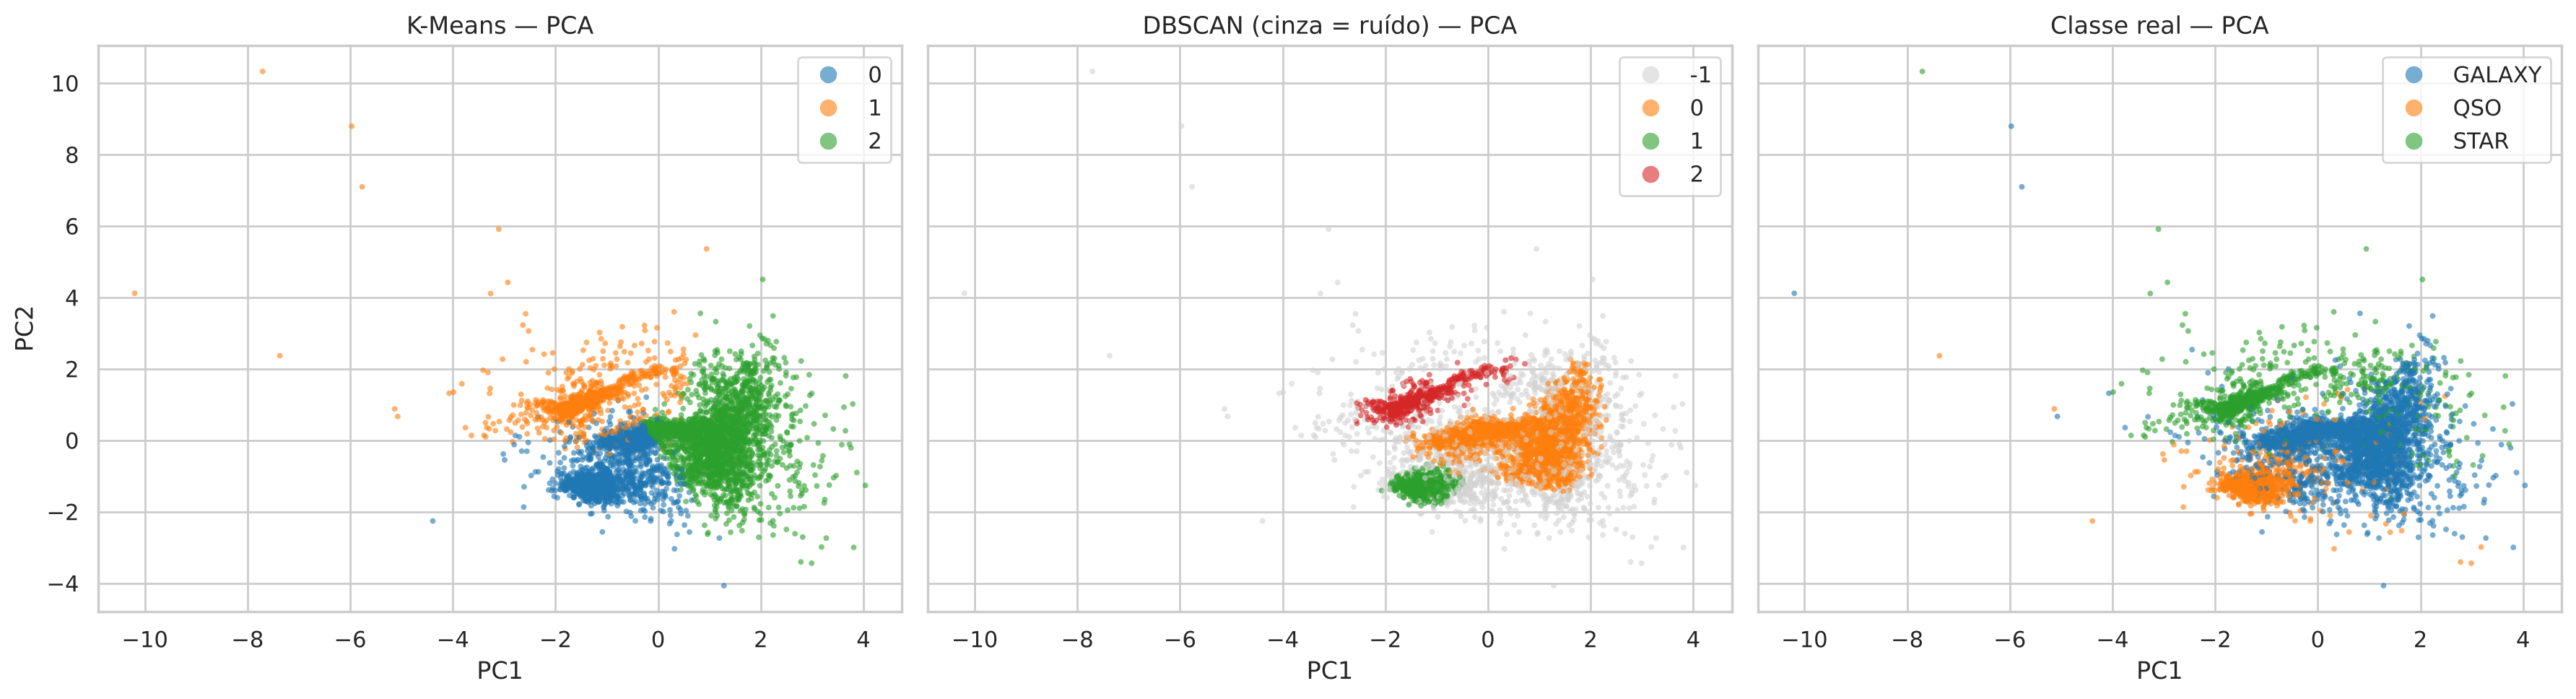

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_scaled)
df['PC1'], df['PC2'] = pcs[:, 0], pcs[:, 1]
print('Variância explicada pelas 2 componentes:', pca.explained_variance_ratio_.sum().round(3))

def paleta(serie):
    cats = sorted(serie.unique())
    cores = sns.color_palette('tab10', len(cats))
    return {c: ('lightgray' if c == -1 else cores[i]) for i, c in enumerate(cats)}

def dispersao(x, y_col, titulo_extra='', ylim=None):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
    for a, col, tit in zip(ax, ['cluster_kmeans', 'cluster_dbscan', 'class'],
                           ['K-Means', 'DBSCAN (cinza = ruído)', 'Classe real']):
        sns.scatterplot(data=df, x=x, y=y_col, hue=col, palette=paleta(df[col]),
                        s=8, alpha=0.6, linewidth=0, ax=a)
        a.set_title(f'{tit}{titulo_extra}')
        a.legend(markerscale=3, title=None)
        if ylim: a.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

dispersao('PC1', 'PC2', ' — PCA')

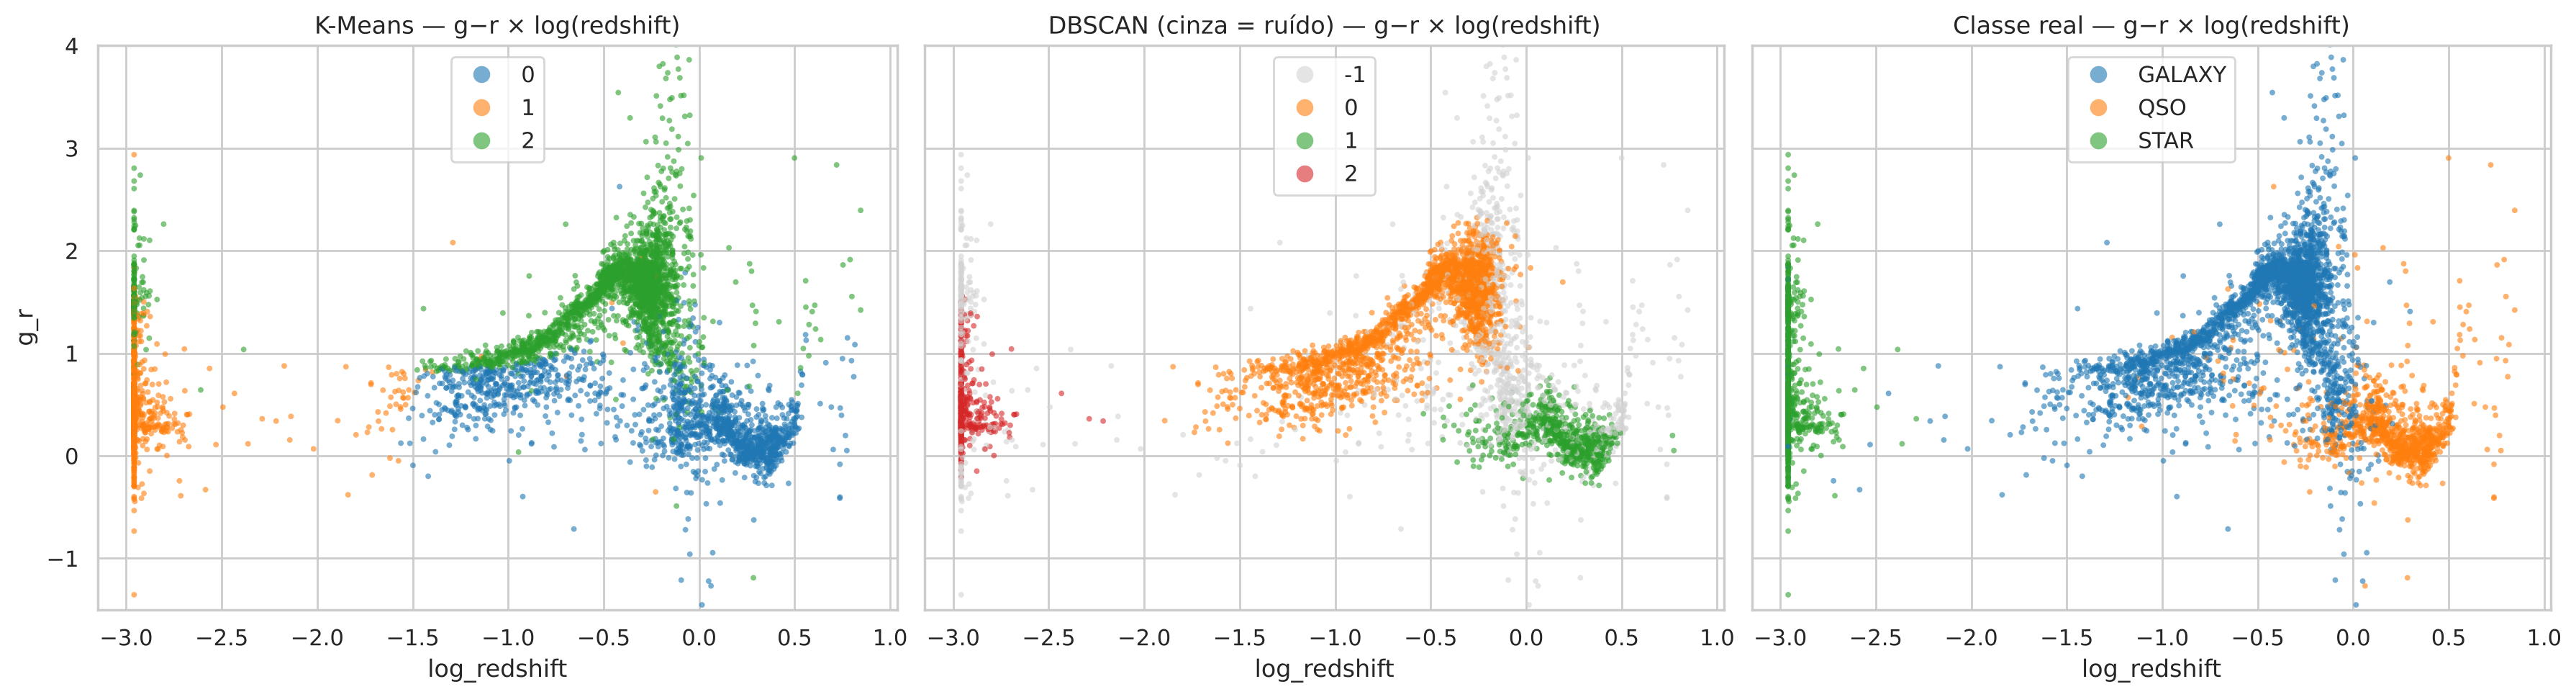

In [10]:
# ylim corta poucos outliers extremos de cor, só para facilitar a visualização
dispersao('log_redshift', 'g_r', ' — g−r × log(redshift)', ylim=(-1.5, 4))

## 5. Correlação entre clusters e atributos (heatmaps)

Duas leituras complementares:
1. **Correlação** entre cada cluster (codificado em 0/1) e cada atributo: mostra quais atributos "definem" cada grupo.
2. **Perfil médio** de cada cluster (atributos padronizados): mostra se o cluster está acima ou abaixo da média em cada atributo.

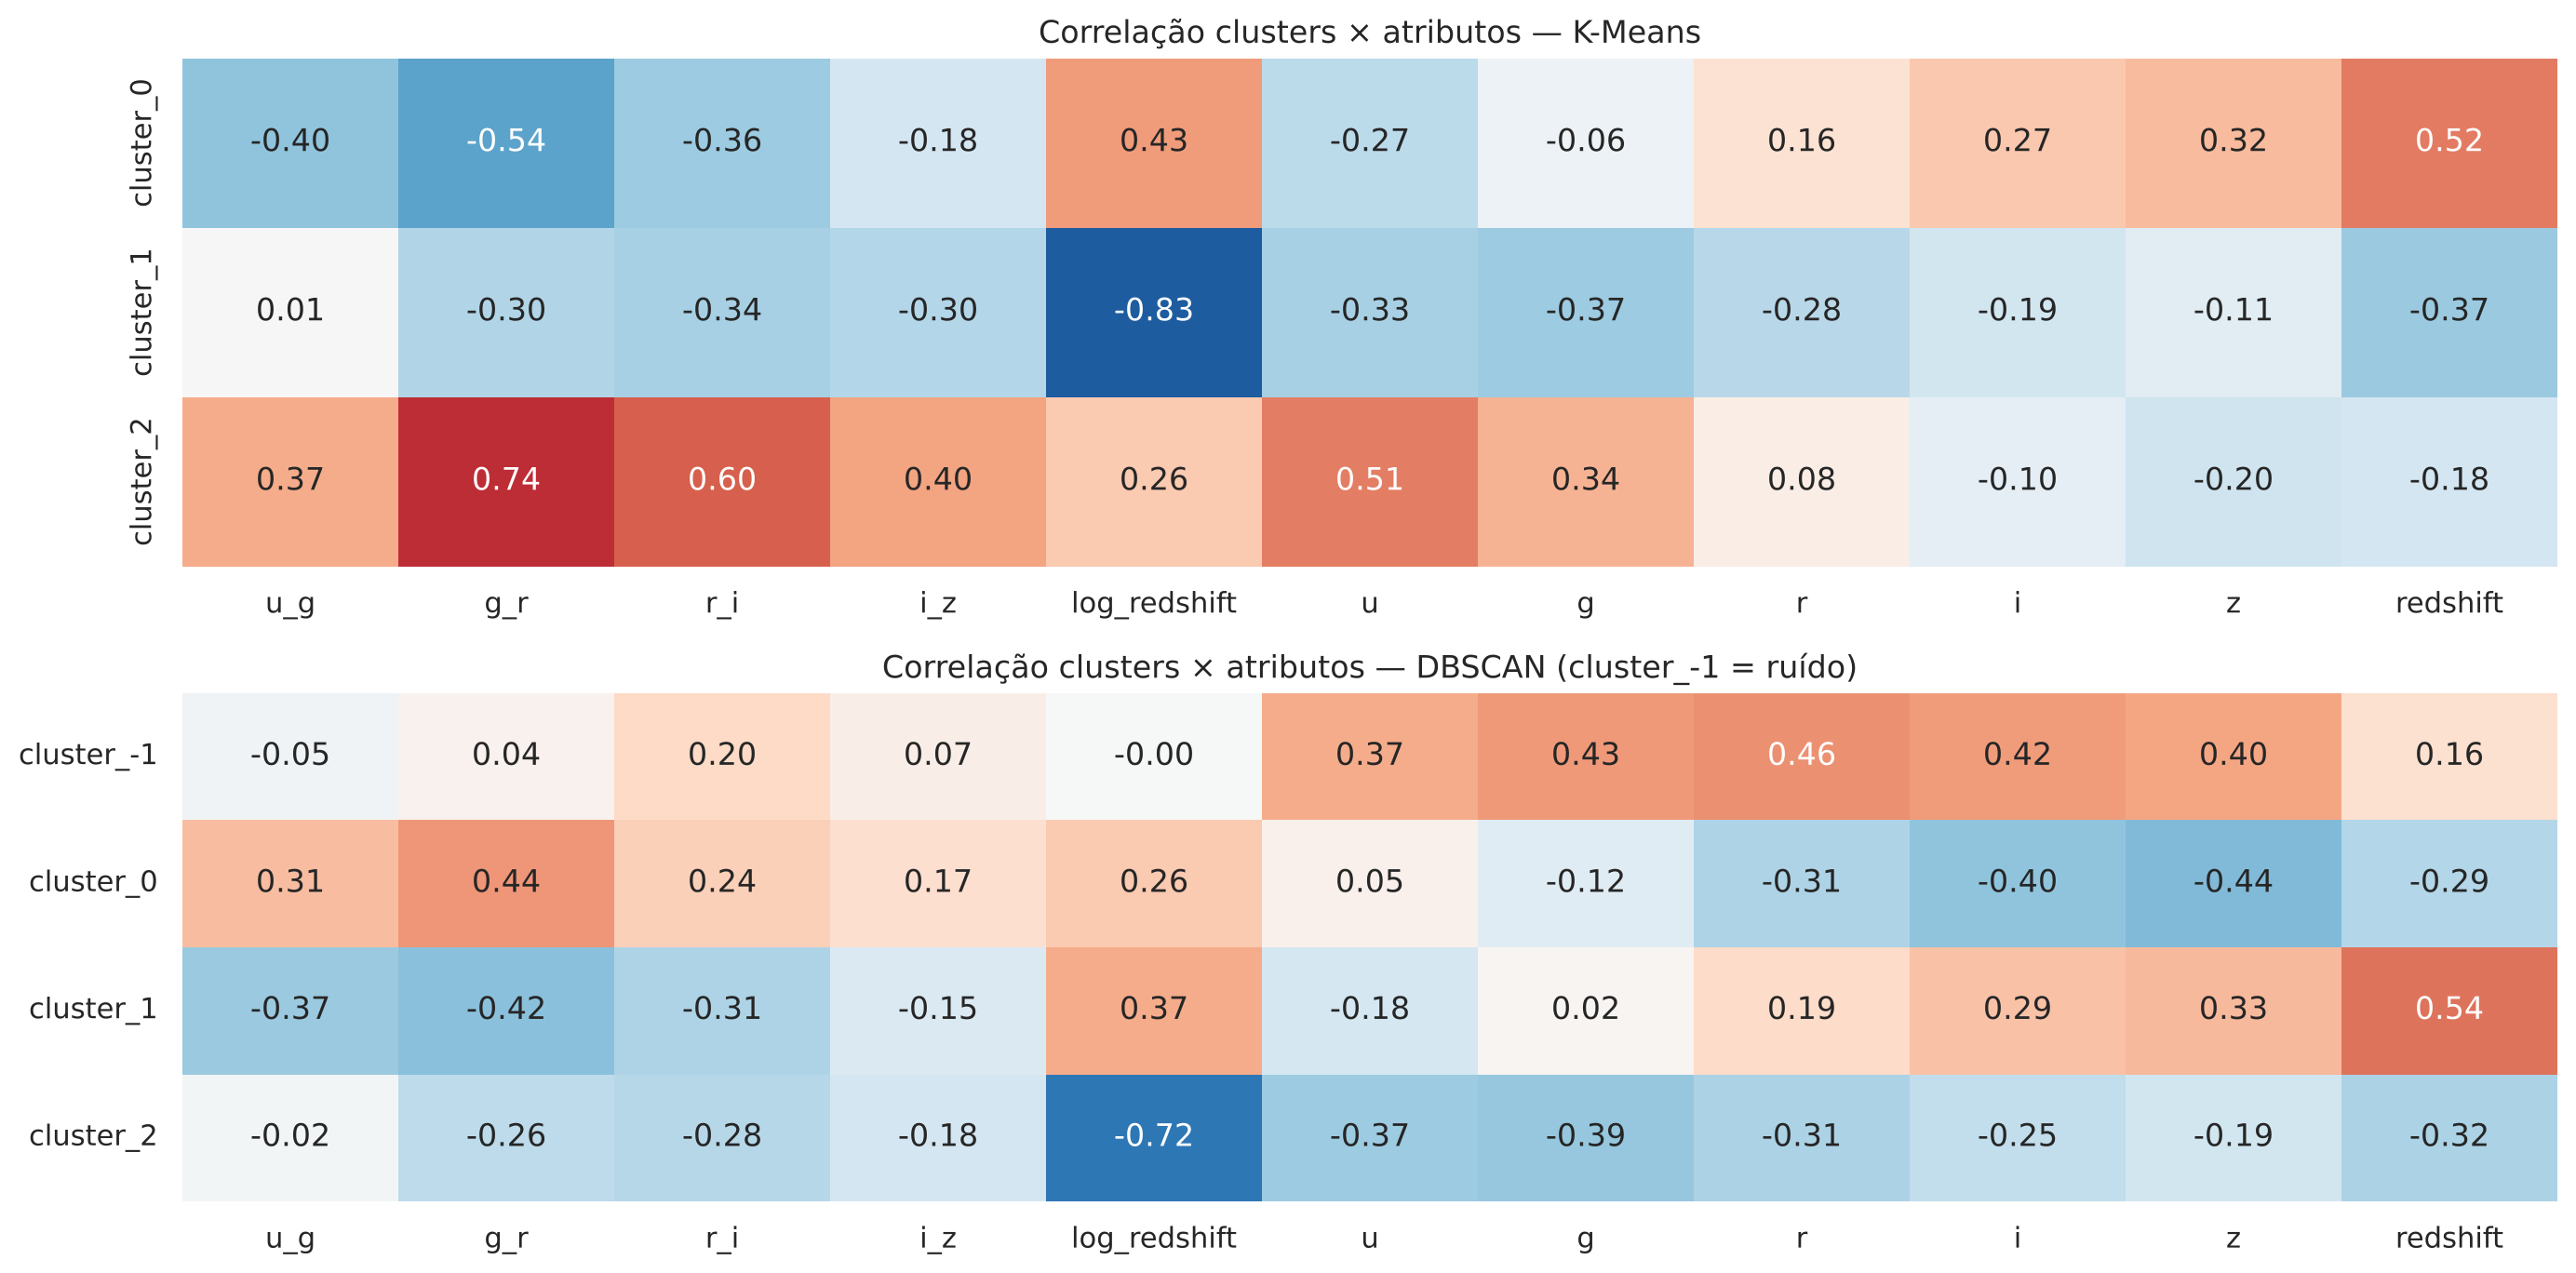

In [11]:
ATRIB_ANALISE = FEATURES + ['u', 'g', 'r', 'i', 'z', 'redshift']

def heatmap_correlacao(col_cluster, titulo, ax):
    dummies = pd.get_dummies(df[col_cluster], prefix='cluster').astype(int)
    corr = pd.concat([dummies, df[ATRIB_ANALISE]], axis=1).corr()
    corr = corr.loc[dummies.columns, ATRIB_ANALISE]
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(titulo)

fig, ax = plt.subplots(2, 1, figsize=(14, 7))
heatmap_correlacao('cluster_kmeans', 'Correlação clusters × atributos — K-Means', ax[0])
heatmap_correlacao('cluster_dbscan', 'Correlação clusters × atributos — DBSCAN (cluster_-1 = ruído)', ax[1])
plt.tight_layout(); plt.show()

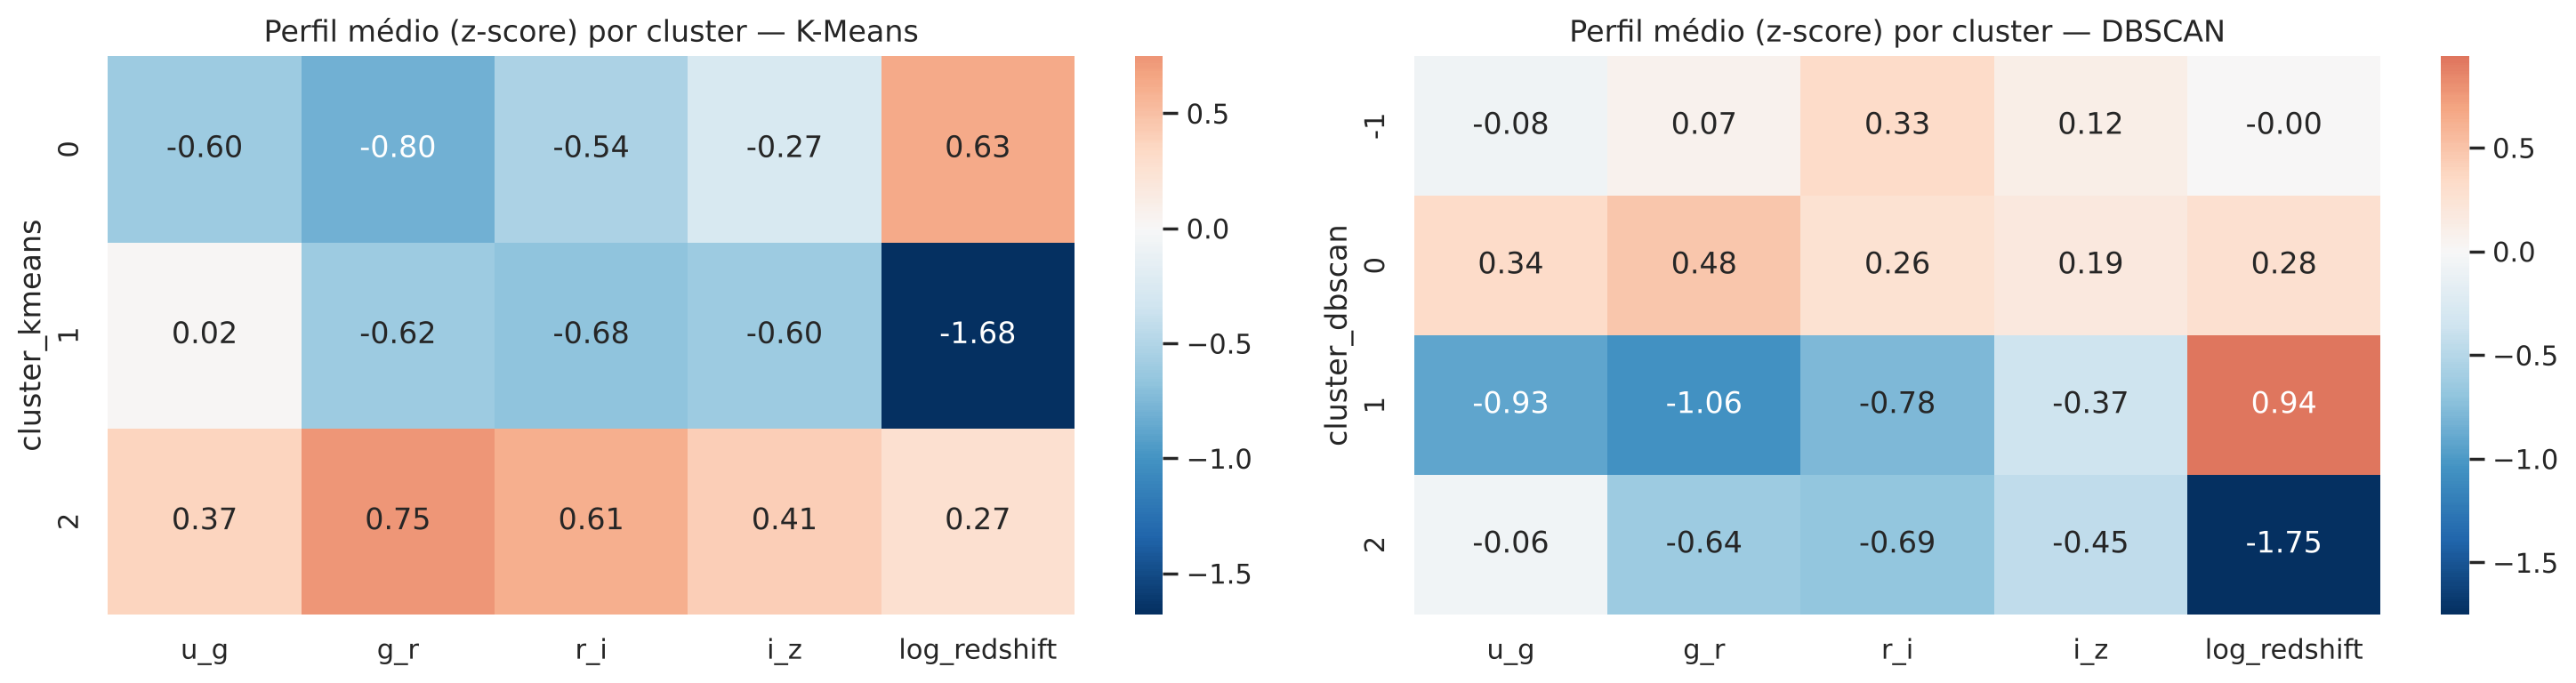

In [12]:
padronizado = pd.DataFrame(X_scaled, columns=FEATURES)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, col, tit in zip(ax, ['cluster_kmeans', 'cluster_dbscan'], ['K-Means', 'DBSCAN']):
    perfil = padronizado.groupby(df[col]).mean()
    sns.heatmap(perfil, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=a)
    a.set_title(f'Perfil médio (z-score) por cluster — {tit}')
plt.tight_layout(); plt.show()

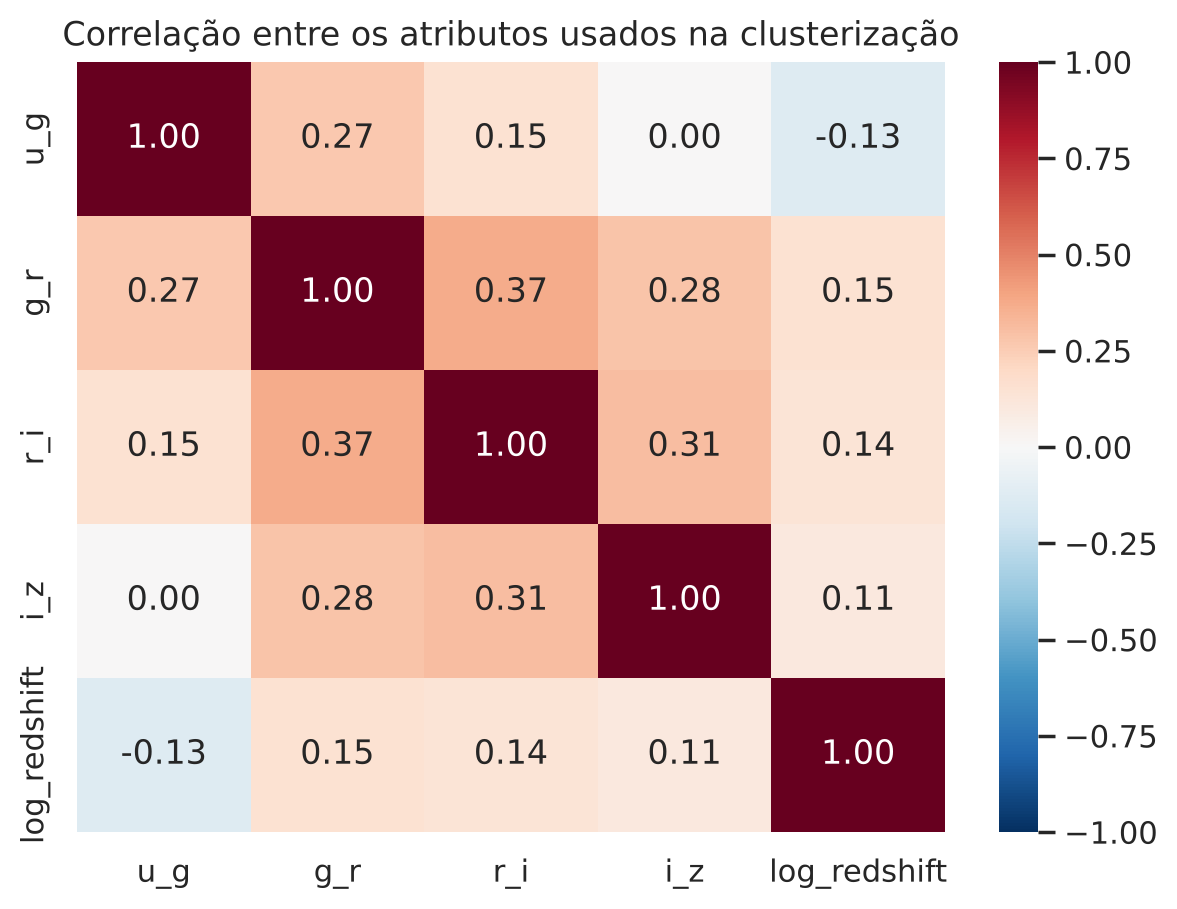

In [13]:
# Para referência: correlação entre os próprios atributos usados
plt.figure(figsize=(7, 5))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlação entre os atributos usados na clusterização')
plt.show()

## 6. Relação entre clusters e classes originais

Agora a coluna `class` volta para a análise. Três perguntas:

1. **Como as classes se distribuem em cada cluster?** (tabela cruzada)
2. **Se cada cluster for "rotulado" com a classe majoritária, qual a acurácia?**
3. **Métricas de concordância** que não dependem do nome dos clusters:
   - **ARI** (Adjusted Rand Index): 0 = aleatório, 1 = partição idêntica
   - **NMI** (Normalized Mutual Information): 0 a 1
   - **Homogeneidade:** cada cluster contém só uma classe?
   - **Completude:** cada classe ficou toda em um único cluster?

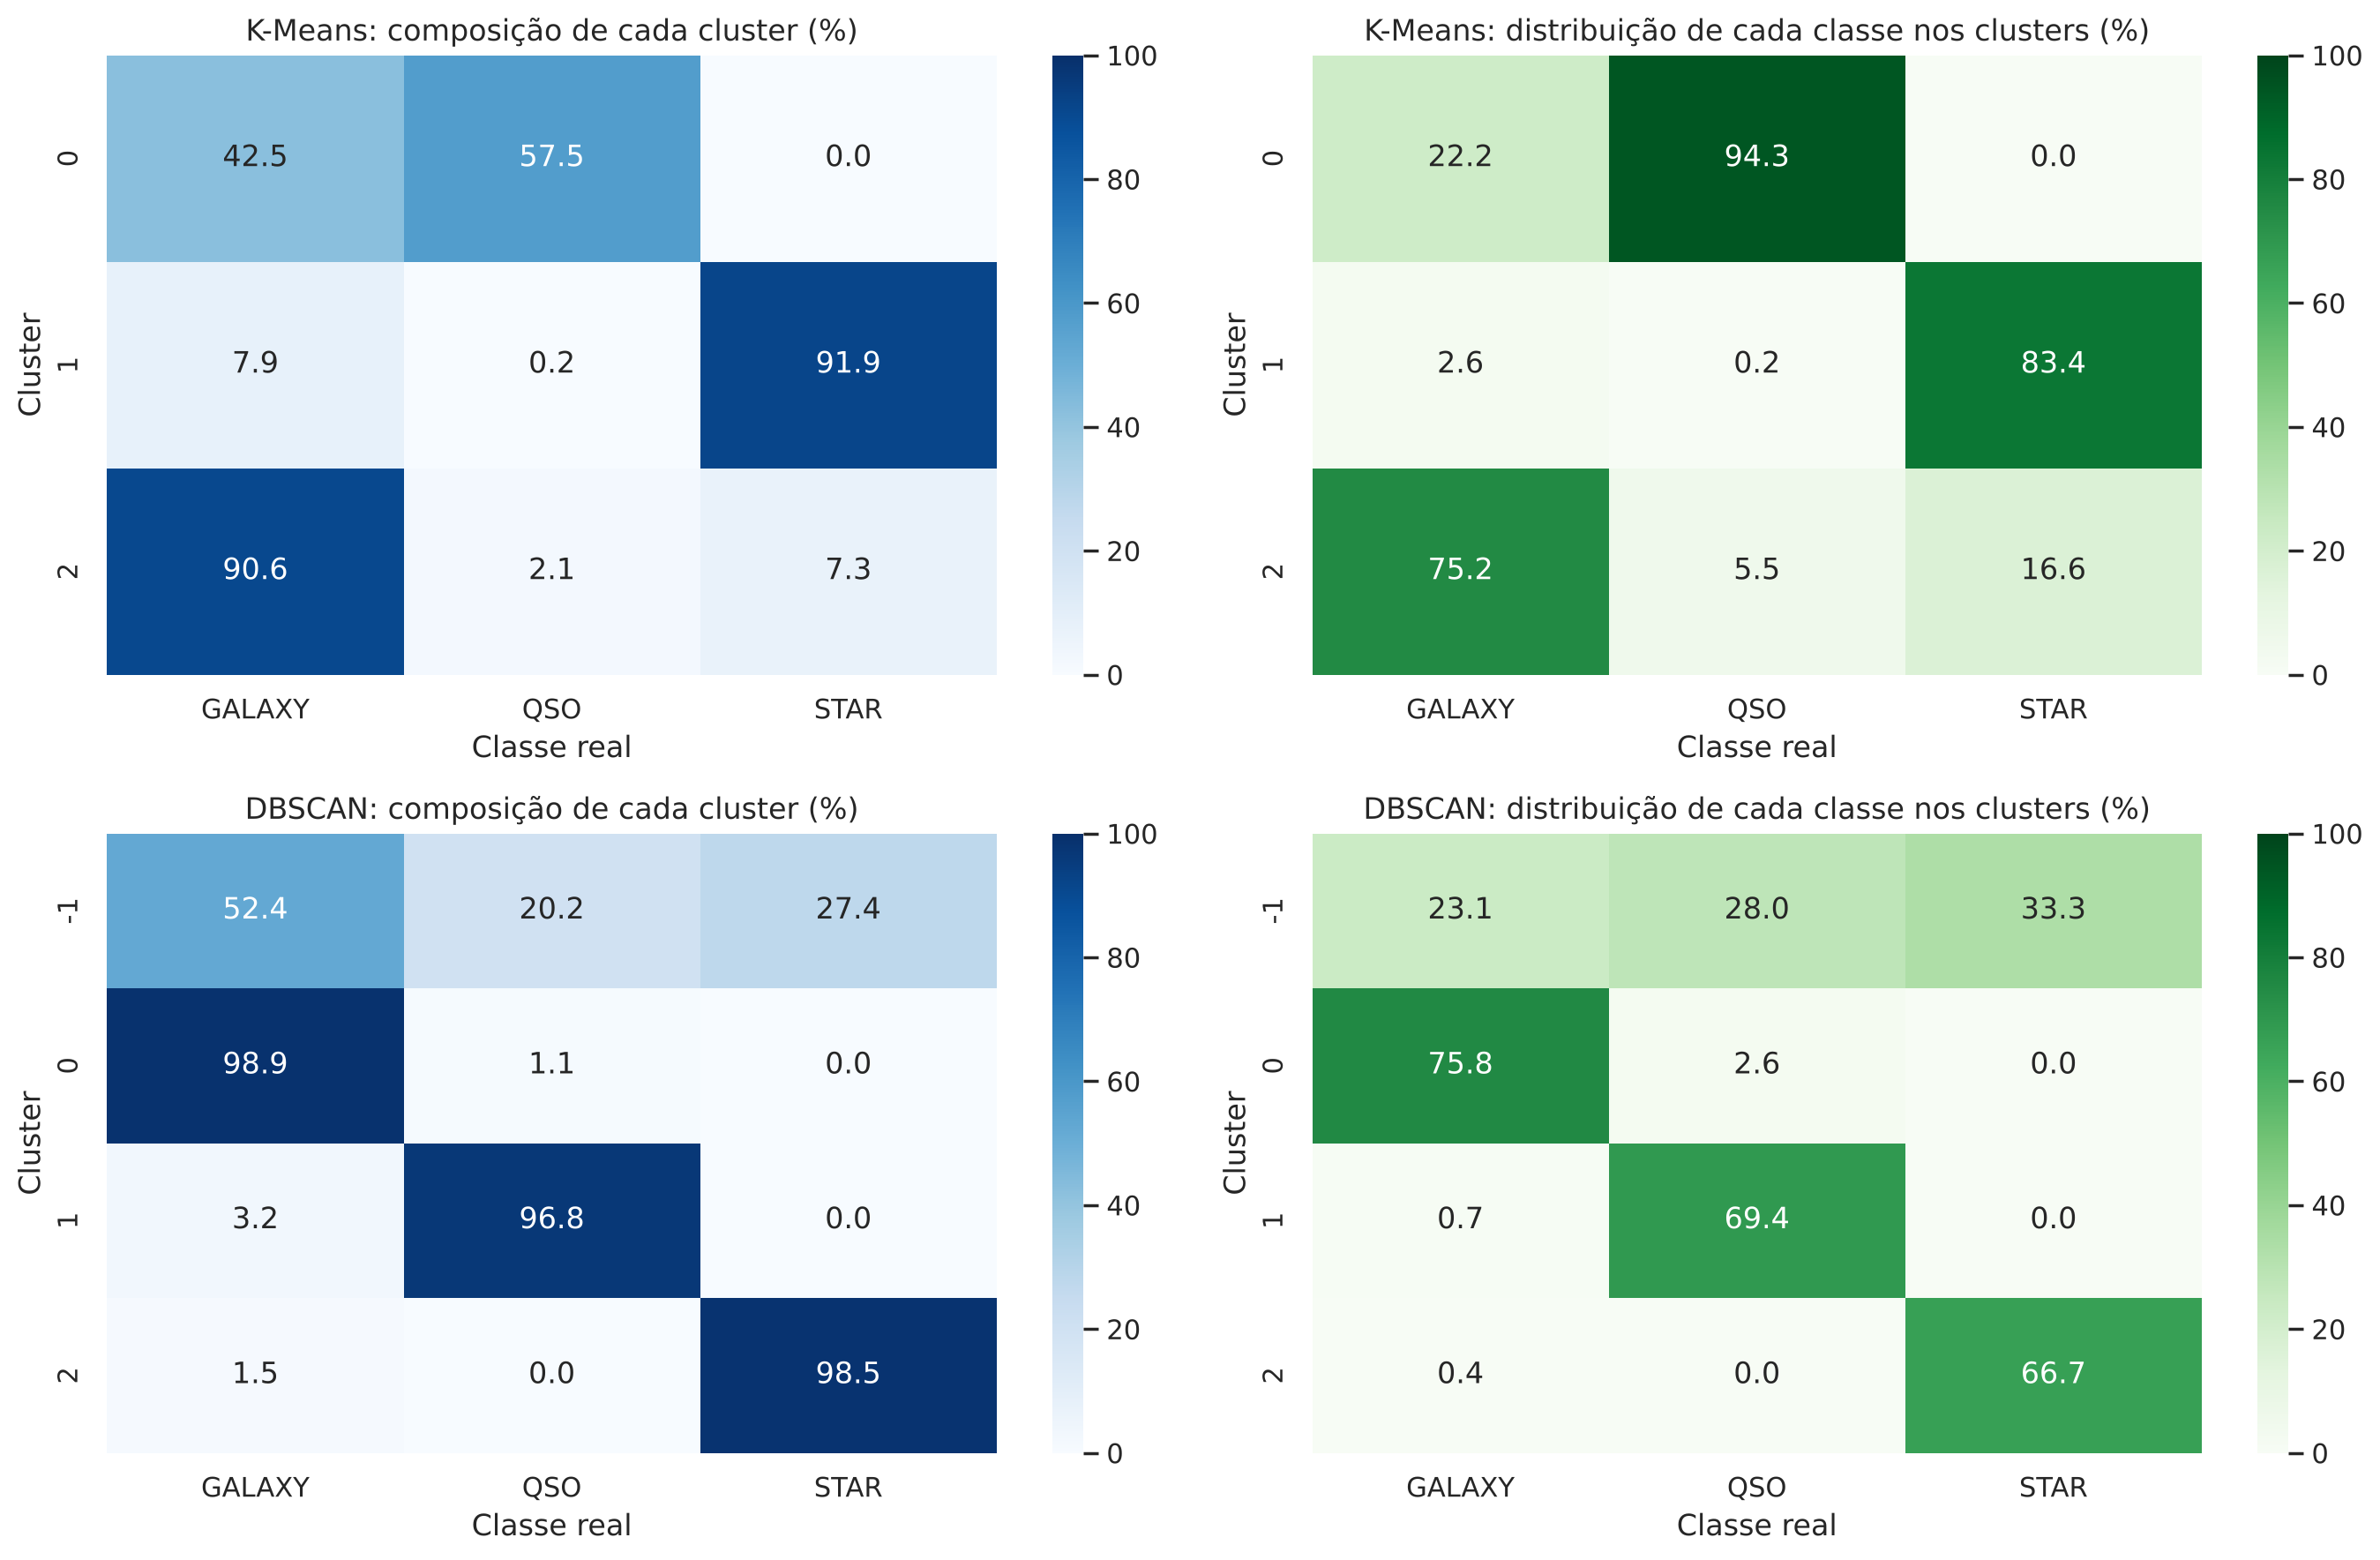

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for i, (col, tit) in enumerate([('cluster_kmeans', 'K-Means'), ('cluster_dbscan', 'DBSCAN')]):
    # Composição de cada cluster (soma 100% por linha)
    ct_linha = pd.crosstab(df[col], y, normalize='index') * 100
    sns.heatmap(ct_linha, annot=True, fmt='.1f', cmap='Blues', ax=ax[i, 0], vmin=0, vmax=100)
    ax[i, 0].set(title=f'{tit}: composição de cada cluster (%)', xlabel='Classe real', ylabel='Cluster')
    # Para onde foi cada classe (soma 100% por coluna)
    ct_col = pd.crosstab(df[col], y, normalize='columns') * 100
    sns.heatmap(ct_col, annot=True, fmt='.1f', cmap='Greens', ax=ax[i, 1], vmin=0, vmax=100)
    ax[i, 1].set(title=f'{tit}: distribuição de cada classe nos clusters (%)', xlabel='Classe real', ylabel='Cluster')
plt.tight_layout(); plt.show()

In [15]:
def avaliar(col, nome, incluir_ruido=True):
    d = df if incluir_ruido else df[df[col] != -1]
    rotulos, verdade = d[col], d['class']
    mapa = pd.crosstab(rotulos, verdade).idxmax(axis=1)   # classe majoritária por cluster
    pred = rotulos.map(mapa)
    if -1 in mapa.index:                                    # ruído não vira classe: conta como erro
        pred = pred.where(rotulos != -1, 'RUÍDO')
    return {'Modelo': nome,
            'Pontos avaliados': len(d),
            'Mapeamento cluster → classe': dict(mapa),
            'Acurácia (classe majoritária)': (pred == verdade).mean(),
            'ARI': adjusted_rand_score(verdade, rotulos),
            'NMI': normalized_mutual_info_score(verdade, rotulos),
            'Homogeneidade': homogeneity_score(verdade, rotulos),
            'Completude': completeness_score(verdade, rotulos)}

metricas = pd.DataFrame([
    avaliar('cluster_kmeans', 'K-Means'),
    avaliar('cluster_dbscan', 'DBSCAN (ruído conta como erro)'),
    avaliar('cluster_dbscan', 'DBSCAN (sem os pontos de ruído)', incluir_ruido=False),
]).set_index('Modelo')
pd.set_option('display.max_colwidth', None)
metricas.round(3)

,Pontos avaliados,Mapeamento cluster → classe,Acurácia (classe majoritária),ARI,NMI,Homogeneidade,Completude
Modelo,,,,,,,
K-Means,5000,"{0: 'QSO', 1: 'STAR', 2: 'GALAXY'}",0.806,0.489,0.512,0.533,0.493
DBSCAN (ruído conta como erro),5000,"{-1: 'GALAXY', 0: 'GALAXY', 1: 'QSO', 2: 'STAR'}",0.726,0.546,0.569,0.660,0.500
DBSCAN (sem os pontos de ruído),3688,"{0: 'GALAXY', 1: 'QSO', 2: 'STAR'}",0.984,0.950,0.914,0.915,0.912


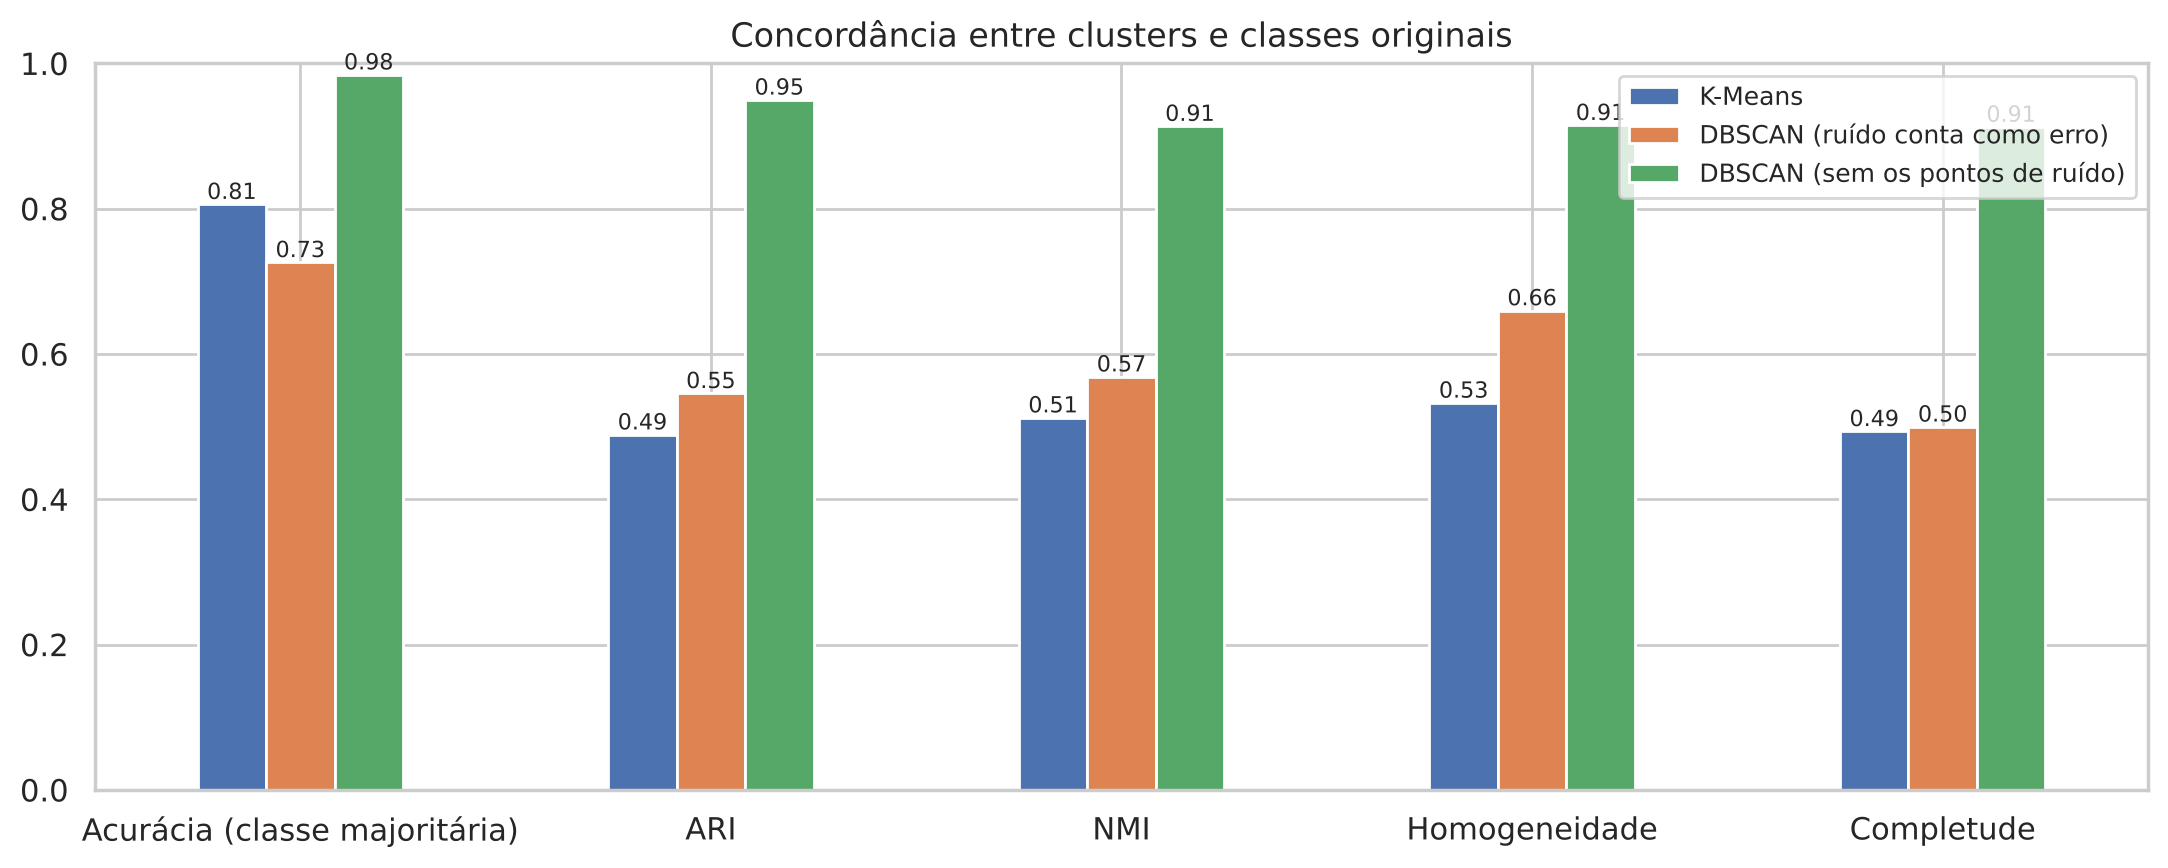

In [16]:
cols = ['Acurácia (classe majoritária)', 'ARI', 'NMI', 'Homogeneidade', 'Completude']
ax = metricas[cols].T.plot(kind='bar', figsize=(11, 4.5), rot=0)
ax.set_ylim(0, 1); ax.set_title('Concordância entre clusters e classes originais')
ax.legend(loc='upper right', fontsize=9)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()

In [17]:
# O ruído do DBSCAN é de qual classe?
ruido = df[df['cluster_dbscan'] == -1]['class'].value_counts(normalize=True).mul(100).round(1)
total = df['class'].value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({'% no ruído do DBSCAN': ruido, '% na amostra toda': total})

,% no ruído do DBSCAN,% na amostra toda
class,,
GALAXY,52.4,59.4
STAR,27.4,21.6
QSO,20.2,19.0


### Comparação: e se usássemos os atributos originais?

Mesmo K-Means e DBSCAN, mas com as 8 colunas usadas nas atividades de classificação (`alpha, delta, u, g, r, i, z, redshift`).

In [18]:
ORIGINAIS = ['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift']
X_orig = StandardScaler().fit_transform(df[ORIGINAIS])
km_orig = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit_predict(X_orig)

# DBSCAN com a mesma regra de escolha (3 clusters, até 30% de ruído, clusters ≥ 5%, maior silhueta)
melhor_orig = None
for eps in np.arange(0.20, 1.51, 0.05):
    for ms in [5, 10, 15, 20, 30]:
        l = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_orig)
        n_cl = len(set(l)) - (1 if -1 in l else 0)
        ok_tam = n_cl and pd.Series(l[l != -1]).value_counts(normalize=True).min() >= 0.05
        if n_cl == N_CLUSTERS and (l == -1).mean() <= 0.30 and ok_tam:
            s = silhouette_score(X_orig[l != -1], l[l != -1])
            if melhor_orig is None or s > melhor_orig[0]:
                melhor_orig = (s, l)
db_orig = melhor_orig[1] if melhor_orig else None
if db_orig is None:
    print('DBSCAN com atributos originais: nenhuma combinação gerou 3 clusters válidos.')

comp = pd.DataFrame({
    'ARI': [adjusted_rand_score(y, km_orig), adjusted_rand_score(y, df['cluster_kmeans']),
            adjusted_rand_score(y, db_orig) if db_orig is not None else np.nan, adjusted_rand_score(y, df['cluster_dbscan'])],
    'NMI': [normalized_mutual_info_score(y, km_orig), normalized_mutual_info_score(y, df['cluster_kmeans']),
            normalized_mutual_info_score(y, db_orig) if db_orig is not None else np.nan, normalized_mutual_info_score(y, df['cluster_dbscan'])],
}, index=['K-Means — atributos originais', 'K-Means — cores + log(redshift)',
          'DBSCAN — atributos originais', 'DBSCAN — cores + log(redshift)'])
comp.round(3)

DBSCAN com atributos originais: nenhuma combinação gerou 3 clusters válidos.


,ARI,NMI
K-Means — atributos originais,0.268,0.326
K-Means — cores + log(redshift),0.489,0.512
DBSCAN — atributos originais,NaN,NaN
DBSCAN — cores + log(redshift),0.546,0.569


## 7. Conclusões

*(Números da execução com `random_state = 42` e amostra estratificada de 5.000 objetos.)*

**1. A representação dos dados pesou mais que o algoritmo.** Com as 8 colunas originais, a posição no céu (`alpha`, `delta`) e o brilho dominam as distâncias: o K-Means fica com ARI ≈ 0,27, e o DBSCAN nem consegue formar 3 clusters válidos. Usando **cores** (diferenças entre filtros) e **log do redshift**, que são as grandezas físicas que distinguem os objetos, o ARI do K-Means sobe para ≈ 0,49.

**2. K-Means (acurácia por classe majoritária ≈ 81%, ARI ≈ 0,49).**
- Um cluster é quase só de **estrelas** (≈ 92% de pureza), definido pelo redshift ≈ 0.
- Outro é de **galáxias** (≈ 91% de pureza), com as cores mais "vermelhas" (g−r alto).
- O terceiro captura **94% dos quasares**, mas também ≈ 22% das galáxias (as de redshift mais alto). Por isso ele é só ≈ 58% QSO.
- A principal fonte de erro é a **confusão galáxia × quasar**. O K-Means assume grupos "esféricos" de tamanho parecido, enquanto aqui as classes formam faixas alongadas e a base é desbalanceada (≈ 60% galáxias).

**3. DBSCAN (eps = 0,45, min_samples = 30).**
- Separa **26% dos pontos como ruído**. Os três clusters restantes são quase puros: **≈ 99% galáxias, ≈ 97% quasares e ≈ 98% estrelas**.
- Nos pontos agrupados, a acurácia é ≈ 98% e o ARI ≈ 0,95, quase o nível dos modelos supervisionados. Contando o ruído como erro, a acurácia cai para ≈ 73% (ARI ≈ 0,55).
- O ruído vem das três classes em proporção parecida à da base. São os pontos das regiões de transição (por exemplo, galáxias de redshift alto perto dos quasares) e os de cores atípicas, exatamente onde o K-Means mais erra.
- Ponto fraco: o resultado é muito sensível a `eps` e `min_samples`. Sem a restrição de tamanho mínimo dos clusters, a melhor silhueta era uma solução inútil (um cluster com 97% dos pontos).

**4. Os clusters chegam às classes?** Sim, em boa parte e sem nenhum rótulo. As três classes aparecem como grupos naturais nos dados. O K-Means força todos os pontos em um grupo e mistura galáxias com quasares. O DBSCAN prefere "não opinar" sobre os pontos ambíguos e acerta quase tudo no que agrupa. Os dois ficam abaixo dos modelos supervisionados das atividades anteriores (acima de 95% na base inteira), porque a fronteira galáxia × quasar não coincide com as regiões de densidade e só a supervisão "ensina" onde ela fica.